# Dana’s Bakery order graph

Run the cells from top to bottom in Google Colab. The graph validates each form submission, checks stock for the whole order, and considers up to two substitutions. Avi’s final pricing rule gives 15% off baked goods above ₪150 except on Fridays. Jerusalem delivery costs ₪20.

Each invocation uses the same opening stock snapshot. The order logic uses deterministic Python and needs no API key. The diagram cell uses the online Mermaid renderer.

In [ ]:
%pip install -q langgraph

## Define and compile the graph

The graph keeps the original request and current candidate in its internal state. Its public output contains the six fields the form needs. The `steps` list records the actual path, including the product at every stock check and substitution.

In [1]:
from typing import Literal, TypedDict

from langgraph.graph import END, START, StateGraph


PRICES_AGOROT = {"challah": 1800, "babka": 4500, "rugelach": 3000, "sourdough": 2500}
OPENING_STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
NEXT_OFFER = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}
WEEKDAYS = {"monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}
MAX_OFFERS = 2


class OrderInput(TypedDict, total=False):
    item: str
    quantity: int
    day: str
    city: str | None


class OrderResult(TypedDict):
    status: Literal["accepted", "rejected"]
    item: str | None
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]


class OrderState(OrderInput, total=False):
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]
    requested_item: str
    candidate: str
    offers: int
    route: str


def normalize(value):
    return value.strip().casefold() if isinstance(value, str) else ""


def record(state: OrderState, step: str) -> list[str]:
    return [*state["steps"], step]


def validate(state: OrderState) -> dict:
    item = normalize(state.get("item"))
    quantity = state.get("quantity")
    day = normalize(state.get("day"))
    city = state.get("city")
    update = {"steps": ["validate"]}
    if (
        item not in PRICES_AGOROT
        or type(quantity) is not int
        or quantity <= 0
        or day not in WEEKDAYS
        or (city is not None and not isinstance(city, str))
    ):
        return {
            **update,
            "route": "invalid",
            "message": "Sorry, we couldn’t understand your order. Please check the form and try again.",
        }
    return {
        **update,
        "route": "valid",
        "requested_item": item,
        "candidate": item,
        "offers": 0,
        "day": day,
        "city": normalize(city),
    }


def substitute(state: OrderState) -> dict:
    candidate = NEXT_OFFER[state["candidate"]]
    return {
        "candidate": candidate,
        "offers": state["offers"] + 1,
        "steps": record(state, f"substitute: {candidate}"),
    }


def fulfill(state: OrderState) -> dict:
    delivery = "delivery" if state["city"] == "jerusalem" else "pickup"
    return {
        "item": state["candidate"],
        "delivery": delivery,
        "steps": record(state, "fulfill"),
    }


def price(state: OrderState) -> dict:
    subtotal = PRICES_AGOROT[state["candidate"]] * state["quantity"]
    if subtotal > 15000 and state["day"] != "friday":
        subtotal = subtotal * 85 // 100
    fee = 2000 if state["delivery"] == "delivery" else 0
    return {"total": (subtotal + fee) / 100, "steps": record(state, "price")}


def accept(state: OrderState) -> dict:
    item = state["candidate"]
    message = f"Thanks for ordering from Dana’s Bakery! We’ve confirmed {state['quantity']} × {item}."
    if item != state["requested_item"]:
        message += f" We substituted {item} because we didn’t have enough {state['requested_item']}."
    if state["delivery"] == "delivery":
        message += " We’ll deliver your order in Jerusalem."
    elif state["city"]:
        message += " We deliver only in Jerusalem, so we’ve switched your order to pickup."
    else:
        message += " We’ll have your order ready for pickup."
    message += f" Your total is ₪{state['total']:.2f}."
    return {"status": "accepted", "message": message, "steps": record(state, "accept")}


def reject(state: OrderState) -> dict:
    return {
        "status": "rejected",
        "item": None,
        "delivery": "pickup",
        "total": 0,
        "message": state["message"],
        "steps": record(state, "reject"),
    }


def build_graph(stock):
    snapshot = dict(stock)

    def check_stock(state: OrderState) -> dict:
        candidate = state["candidate"]
        update = {"steps": record(state, f"check_stock: {candidate}")}
        if snapshot[candidate] >= state["quantity"]:
            return {**update, "route": "in stock"}
        if state["offers"] < MAX_OFFERS and candidate in NEXT_OFFER:
            return {**update, "route": "try substitute"}
        return {
            **update,
            "route": "out of stock",
            "message": (
                f"Sorry, we couldn’t fill your order for {state['quantity']} × "
                f"{state['requested_item']} with the stock available. We’ve cancelled the order."
            ),
        }

    def route(state: OrderState) -> str:
        return state["route"]

    builder = StateGraph(OrderState, input_schema=OrderInput, output_schema=OrderResult)
    builder.add_node("validate", validate)
    builder.add_node("check_stock", check_stock)
    builder.add_node("substitute", substitute)
    builder.add_node("fulfill", fulfill)
    builder.add_node("price", price)
    builder.add_node("accept", accept)
    builder.add_node("reject", reject)

    builder.add_edge(START, "validate")
    builder.add_conditional_edges("validate", route, {"valid": "check_stock", "invalid": "reject"})
    builder.add_conditional_edges(
        "check_stock",
        route,
        {"in stock": "fulfill", "try substitute": "substitute", "out of stock": "reject"},
    )
    builder.add_edge("substitute", "check_stock")
    builder.add_edge("fulfill", "price")
    builder.add_edge("price", "accept")
    builder.add_edge("accept", END)
    builder.add_edge("reject", END)
    return builder.compile()


graph = build_graph(OPENING_STOCK)

## Display the compiled graph

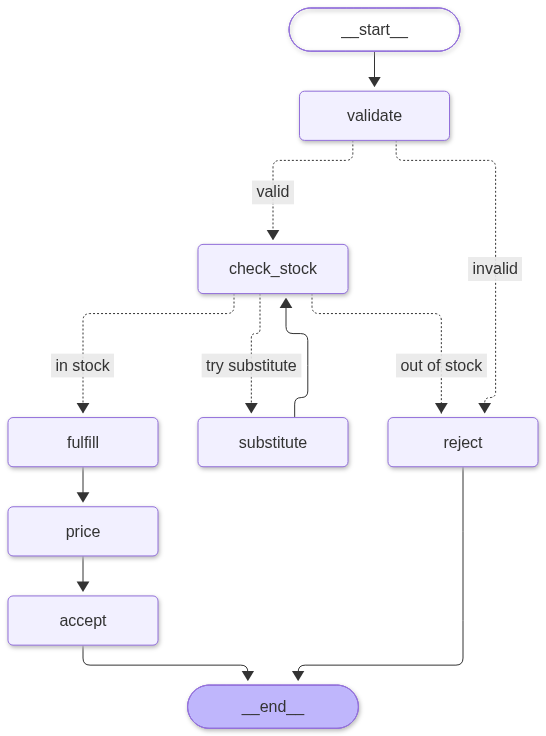

In [2]:
from IPython.display import Image, display

display(Image(data=graph.get_graph().draw_mermaid_png()))

## Try the order paths

The assertions check each order’s result, customer reply, and complete trace. A separate stock fixture isolates the ₪150 boundary while leaving the bakery’s opening stock intact.

In [3]:
from pprint import pprint


RESULT_KEYS = {"status", "item", "delivery", "total", "message", "steps"}
ACCEPT_STEPS = ["fulfill", "price", "accept"]
REJECT_RESULT = ("rejected", None, "pickup", 0)


def check_order(app, item, quantity, day, city, expected, steps, reply_parts):
    order = {"item": item, "quantity": quantity, "day": day, "city": city}
    result = app.invoke(order)
    assert set(result) == RESULT_KEYS, result
    assert tuple(result[key] for key in ("status", "item", "delivery", "total")) == expected, result
    assert result["steps"] == steps, result
    for text in reply_parts:
        assert text in result["message"], result
    pprint(order)
    pprint(result)
    print()


check_order(
    graph, " ChALLaH ", 2, " Thursday ", " ",
    ("accepted", "challah", "pickup", 36),
    ["validate", "check_stock: challah", *ACCEPT_STEPS],
    ["2 × challah", "ready for pickup", "₪36.00"],
)
check_order(
    graph, "babka", 2, "Thursday", "Jerusalem",
    ("accepted", "rugelach", "delivery", 80),
    ["validate", "check_stock: babka", "substitute: rugelach", "check_stock: rugelach", *ACCEPT_STEPS],
    ["2 × rugelach", "substituted rugelach", "deliver your order in Jerusalem", "₪80.00"],
)
check_order(
    graph, "babka", 4, "Thursday", "Tel Aviv",
    ("accepted", "sourdough", "pickup", 100),
    [
        "validate", "check_stock: babka", "substitute: rugelach", "check_stock: rugelach",
        "substitute: sourdough", "check_stock: sourdough", *ACCEPT_STEPS,
    ],
    ["4 × sourdough", "substituted sourdough", "switched your order to pickup", "₪100.00"],
)
check_order(
    graph, "babka", 5, "Thursday", "Jerusalem",
    REJECT_RESULT,
    [
        "validate", "check_stock: babka", "substitute: rugelach", "check_stock: rugelach",
        "substitute: sourdough", "check_stock: sourdough", "reject",
    ],
    ["5 × babka", "cancelled"],
)
check_order(
    graph, "challah", 11, "Thursday", "",
    REJECT_RESULT,
    ["validate", "check_stock: challah", "reject"],
    ["11 × challah", "cancelled"],
)
for day, total in [("Thursday", 173), ("Friday", 200)]:
    check_order(
        graph, "challah", 10, day, " JERUSALEM ",
        ("accepted", "challah", "delivery", total),
        ["validate", "check_stock: challah", *ACCEPT_STEPS],
        ["deliver your order in Jerusalem", f"₪{total:.2f}"],
    )

threshold_graph = build_graph({**OPENING_STOCK, "sourdough": 6})
check_order(
    threshold_graph, "sourdough", 6, "Thursday", "Jerusalem",
    ("accepted", "sourdough", "delivery", 170),
    ["validate", "check_stock: sourdough", *ACCEPT_STEPS],
    ["6 × sourdough", "₪170.00"],
)

for item, quantity in [
    ("pizza", 1), ("croissants", 1), ("challah", 0),
    ("babka", -2), ("challah", 1.5), ("challah", True),
]:
    check_order(
        graph, item, quantity, "Thursday", "",
        REJECT_RESULT,
        ["validate", "reject"],
        ["couldn’t understand your order"],
    )

print("All 14 order cases passed.")

{'city': ' ', 'day': ' Thursday ', 'item': ' ChALLaH ', 'quantity': 2}
{'delivery': 'pickup',
 'item': 'challah',
 'message': 'Thanks for ordering from Dana’s Bakery! We’ve confirmed 2 × '
            'challah. We’ll have your order ready for pickup. Your total is '
            '₪36.00.',
 'status': 'accepted',
 'steps': ['validate', 'check_stock: challah', 'fulfill', 'price', 'accept'],
 'total': 36.0}

{'city': 'Jerusalem', 'day': 'Thursday', 'item': 'babka', 'quantity': 2}
{'delivery': 'delivery',
 'item': 'rugelach',
 'message': 'Thanks for ordering from Dana’s Bakery! We’ve confirmed 2 × '
            'rugelach. We substituted rugelach because we didn’t have enough '
            'babka. We’ll deliver your order in Jerusalem. Your total is '
            '₪80.00.',
 'status': 'accepted',
 'steps': ['validate',
           'check_stock: babka',
           'substitute: rugelach',
           'check_stock: rugelach',
           'fulfill',
           'price',
           'accept'],
 'total